In [ ]:
from google.colab import files
uploaded = files.upload()

Saving superstore_final_dataset (1).csv to superstore_final_dataset (1).csv


In [ ]:
import os
print(os.listdir())

['.config', 'superstore_final_dataset (1).csv', 'sample_data']


In [ ]:
df = pd.read_csv("superstore_final_dataset (1).csv", encoding="latin1")

In [ ]:
import pandas as pd

df = pd.read_csv("superstore_final_dataset (1).csv", encoding="latin1")

print(df.shape)
df.head()

(9800, 18)


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,1,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/6/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold N Roll Cart System,22.3680


In [ ]:
# Print all column names to see the exact spelling and spacing
print(df.columns.tolist())

['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales']


In [ ]:
# Force print all available columns line by line
for col in df.columns:
    print(f"'{col}'")

'Row_ID'
'Order_ID'
'Order_Date'
'Ship_Date'
'Ship_Mode'
'Customer_ID'
'Customer_Name'
'Segment'
'Country'
'City'
'State'
'Postal_Code'
'Region'
'Product_ID'
'Category'
'Sub_Category'
'Product_Name'
'Sales'


In [ ]:
# 1. Calculate overall Total Sales
total_sales = df['Sales'].sum()
print(f"Total Sales: ${total_sales:,.2f}\n")

# 2. Sales by Product Category
print("--- Sales by Product Category ---")
category_sales = df.groupby('Category')['Sales'].sum().reset_index()
category_sales = category_sales.sort_values(by='Sales', ascending=False)
print(category_sales.to_string(index=False))

# 3. Sales by Region
print("\n--- Sales by Region ---")
region_sales = df.groupby('Region')['Sales'].sum().reset_index()
region_sales = region_sales.sort_values(by='Sales', ascending=False)
print(region_sales.to_string(index=False))

Total Sales: $2,261,536.78

--- Sales by Product Category ---
       Category       Sales
     Technology 827455.8730
      Furniture 728658.5757
Office Supplies 705422.3340

--- Sales by Region ---
 Region       Sales
   West 710219.6845
   East 669518.7260
Central 492646.9132
  South 389151.4590


/tmp/ipykernel_1901/3556128776.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1901/3556128776.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


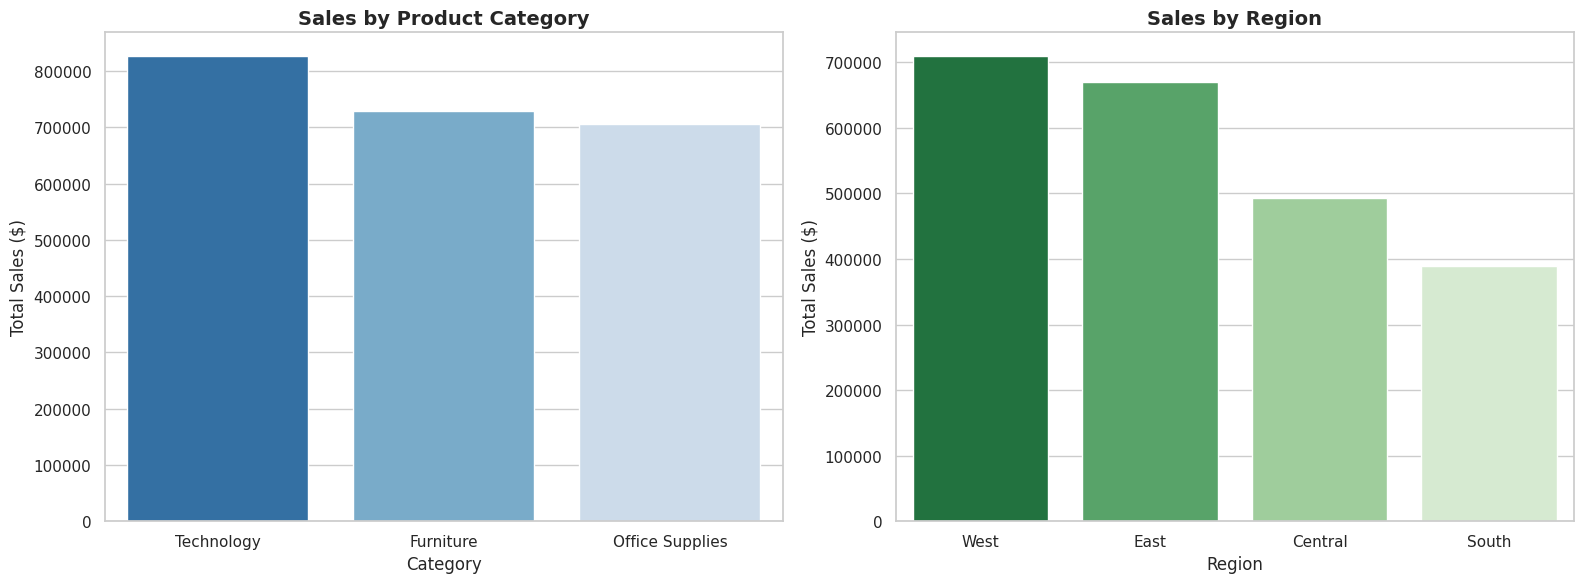

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Sales by Product Category
sns.barplot(
    data=category_sales,
    x='Category',
    y='Sales',
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('Sales by Product Category', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Category', fontsize=12)
axes[0].set_ylabel('Total Sales ($)', fontsize=12)

# Chart 2: Sales by Region
sns.barplot(
    data=region_sales,
    x='Region',
    y='Sales',
    ax=axes[1],
    palette='Greens_r'
)
axes[1].set_title('Sales by Region', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Region', fontsize=12)
axes[1].set_ylabel('Total Sales ($)', fontsize=12)

plt.tight_layout()
plt.show()

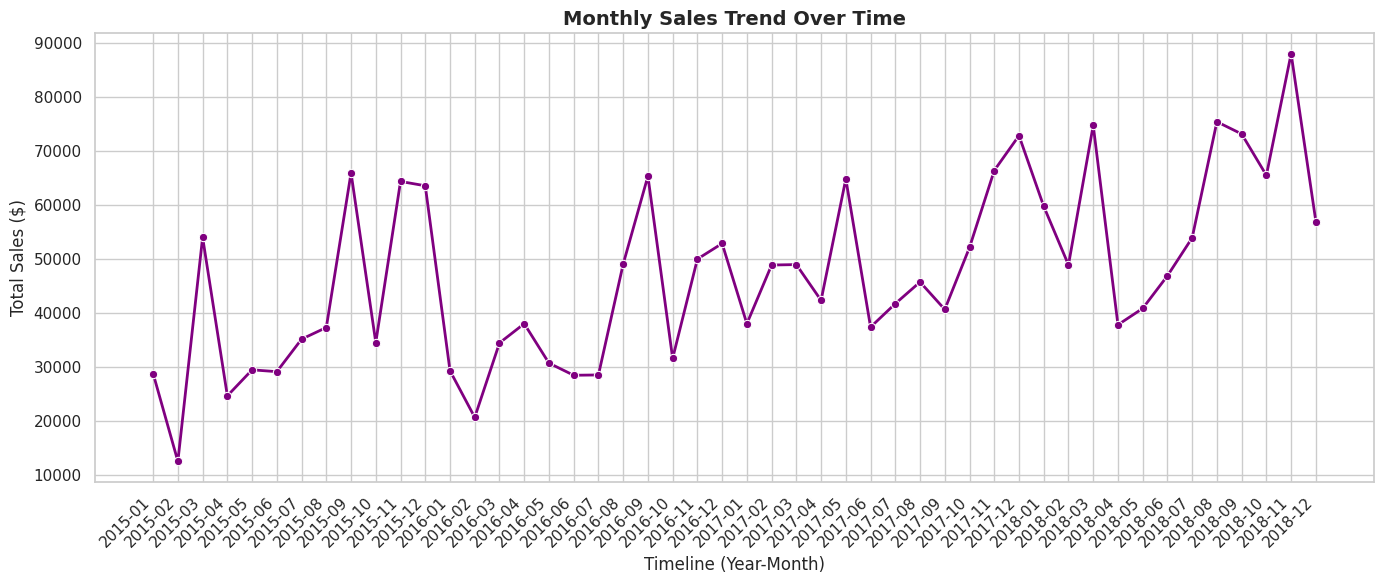

In [ ]:
# 1. Safely convert Order_Date to datetime, automatically handling mixed formats
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce', format='mixed')

# Drop any rows where the date couldn't be parsed at all
df = df.dropna(subset=['Order_Date'])

# 2. Extract Year and Month for chronological sorting
df['Year_Month'] = df['Order_Date'].dt.to_period('M')
monthly_sales = df.groupby('Year_Month')['Sales'].sum().reset_index()
monthly_sales['Year_Month'] = monthly_sales['Year_Month'].astype(str)

# 3. Plot the monthly sales timeline
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_sales,
    x='Year_Month',
    y='Sales',
    marker='o',
    color='purple',
    linewidth=2
)
plt.title('Monthly Sales Trend Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Timeline (Year-Month)', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)

# Rotate the x-axis dates so they don't overlap
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

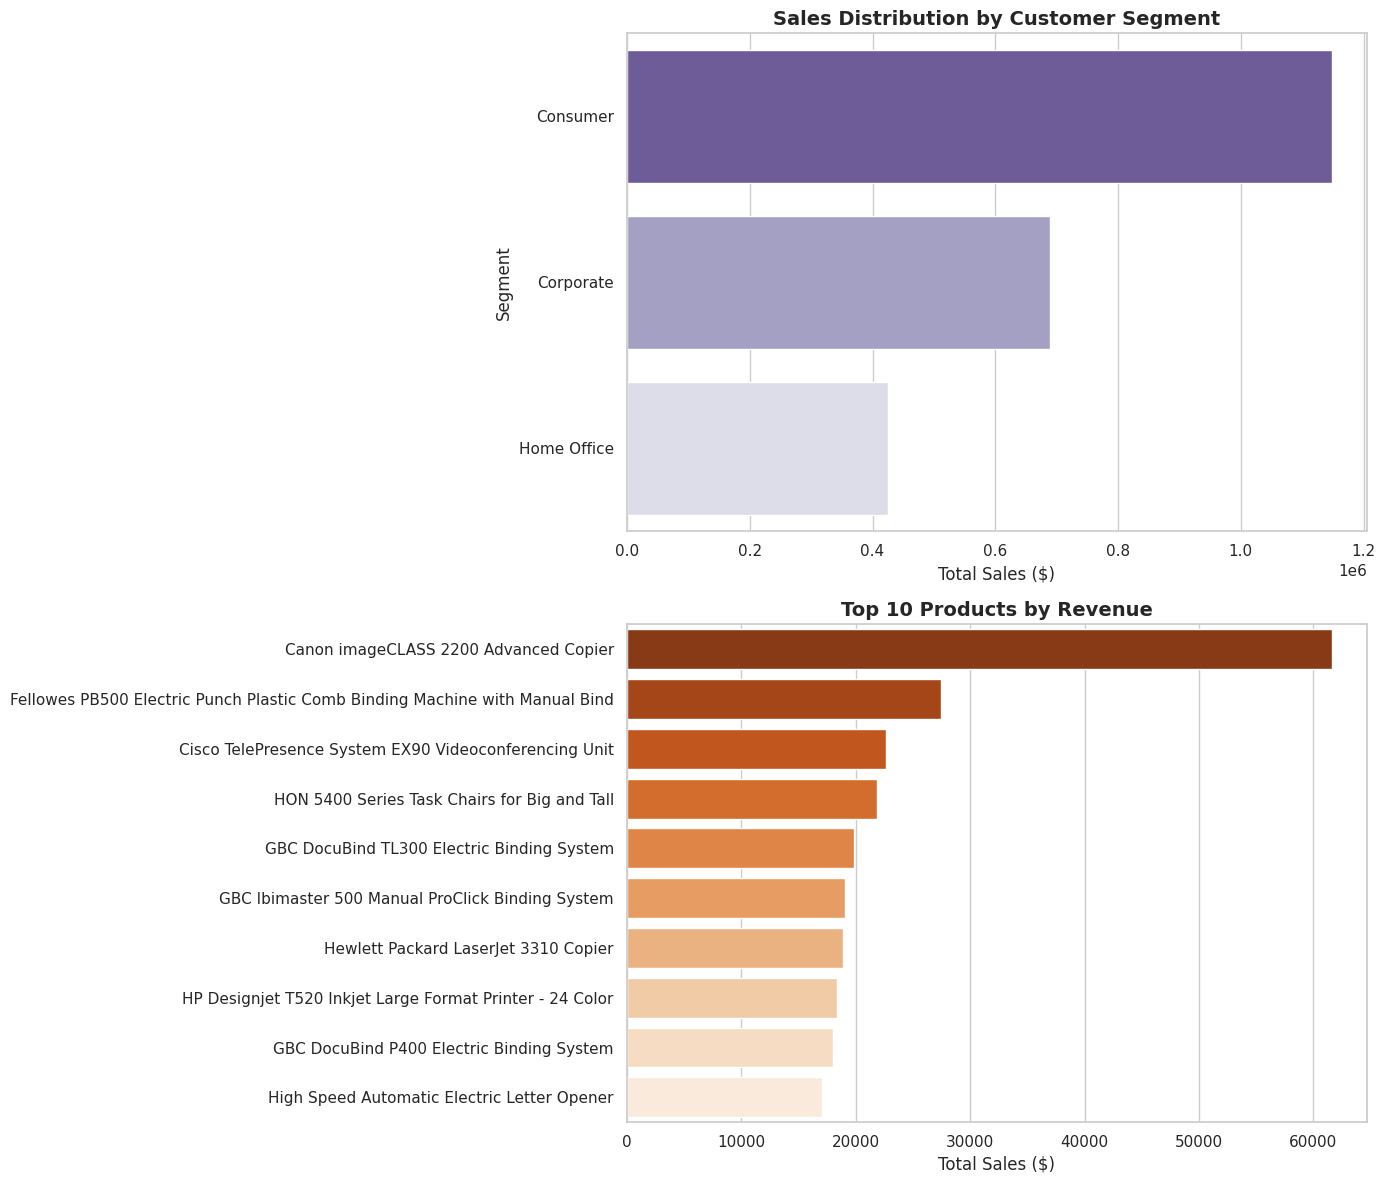

In [ ]:
# Create a new figure space for two final insights
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# 1. Sales by Customer Segment (Corporate vs. Consumer vs. Home Office)
segment_sales = df.groupby('Segment')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False)
sns.barplot(data=segment_sales, x='Sales', y='Segment', ax=axes[0], palette='Purples_r', hue='Segment', legend=False)
axes[0].set_title('Sales Distribution by Customer Segment', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Sales ($)', fontsize=12)
axes[0].set_ylabel('Segment', fontsize=12)

# 2. Top 10 Best-Selling Products by Revenue
top_products = df.groupby('Product_Name')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False).head(10)
sns.barplot(data=top_products, x='Sales', y='Product_Name', ax=axes[1], palette='Oranges_r', hue='Product_Name', legend=False)
axes[1].set_title('Top 10 Products by Revenue', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Sales ($)', fontsize=12)
axes[1].set_ylabel('', fontsize=12) # Leave label blank since product titles are long

plt.tight_layout()
plt.show()

In [ ]:
# 1. Save your processed dataframe to a new CSV file
df.to_csv('superstore_analyzed_data.csv', index=False)
print("Processed data saved successfully as 'superstore_analyzed_data.csv'!")

# 2. How to save your charts as high-res images (run this right before plt.show() next time)
# plt.savefig('sales_performance_dashboard.png', dpi=300, bbox_inches='tight')

Processed data saved successfully as 'superstore_analyzed_data.csv'!


In [ ]:
# 1. Top 10 Customers by Sales Volume
top_customers = df.groupby('Customer_Name')['Sales'].sum().reset_index()
top_customers = top_customers.sort_values(by='Sales', ascending=False).head(10)

print("--- Top 10 Customers by Sales ---")
print(top_customers.to_string(index=False))

# 2. Top 5 Cities by Sales Volume
top_cities = df.groupby('City')['Sales'].sum().reset_index()
top_cities = top_cities.sort_values(by='Sales', ascending=False).head(5)

print("\n--- Top 5 Cities by Sales ---")
print(top_cities.to_string(index=False))

--- Top 10 Customers by Sales ---
     Customer_Name     Sales
       Sean Miller 25043.050
      Tamara Chand 19052.218
      Raymond Buch 15117.339
      Tom Ashbrook 14595.620
     Adrian Barton 14473.571
      Ken Lonsdale 14175.229
      Sanjit Chand 14142.334
      Hunter Lopez 12873.298
      Sanjit Engle 12209.438
Christopher Conant 12129.072

--- Top 5 Cities by Sales ---
         City      Sales
New York City 252462.547
  Los Angeles 173420.181
      Seattle 116106.322
San Francisco 109041.120
 Philadelphia 108841.749


In [ ]:
# Generate a clean executive summary printout
print("==================================================")
print("         EXECUTIVE SALES PERFORMANCE REPORT       ")
print("==================================================")
print(f"• Total Revenue Generated: ${df['Sales'].sum():,.2f}")
print(f"• Total Unique Orders Processed: {df['Order_ID'].nunique():,}")
print(f"• Total Customers Served: {df['Customer_ID'].nunique():,}")
print(f"• Top Performing Region: {region_sales.iloc[0]['Region']} (${region_sales.iloc[0]['Sales']:,.2f})")
print(f"• Top Product Category: {category_sales.iloc[0]['Category']} (${category_sales.iloc[0]['Sales']:,.2f})")
print(f"• Highest Value Market City: {top_cities.iloc[0]['City']} (${top_cities.iloc[0]['Sales']:,.2f})")
print(f"• Top Customer by Spend: {top_customers.iloc[0]['Customer_Name']} (${top_customers.iloc[0]['Sales']:,.2f})")
print("==================================================")

         EXECUTIVE SALES PERFORMANCE REPORT       
• Total Revenue Generated: $2,261,536.78
• Total Unique Orders Processed: 4,922
• Total Customers Served: 793
• Top Performing Region: West ($710,219.68)
• Top Product Category: Technology ($827,455.87)
• Highest Value Market City: New York City ($252,462.55)
• Top Customer by Spend: Sean Miller ($25,043.05)


In [ ]:
# 1. Shipping Mode Performance Analysis
ship_mode_perf = df.groupby('Ship_Mode')['Sales'].agg(['sum', 'count', 'mean']).reset_index()
ship_mode_perf.columns = ['Ship_Mode', 'Total_Sales', 'Order_Count', 'Average_Per_Order']
ship_mode_perf = ship_mode_perf.sort_values(by='Total_Sales', ascending=False)

print("--- Shipping Mode Performance ---")
print(ship_mode_perf.to_string(index=False, formatters={
    'Total_Sales': '{:,.2f}'.format,
    'Order_Count': '{:,}'.format,
    'Average_Per_Order': '{:,.2f}'.format
}))

# 2. Average Order Value (AOV) Calculation
# Groups items bought together in the same transaction order ID
order_totals = df.groupby('Order_ID')['Sales'].sum()
aov = order_totals.mean()

print("\n--------------------------------------------------")
print(f"• Average Order Value (AOV): ${aov:.2f}")
print("--------------------------------------------------")

--- Shipping Mode Performance ---
     Ship_Mode  Total_Sales Order_Count Average_Per_Order
Standard Class 1,340,831.31       5,859            228.85
  Second Class   449,914.18       1,902            236.55
   First Class   345,572.26       1,501            230.23
      Same Day   125,219.04         538            232.75

--------------------------------------------------
• Average Order Value (AOV): $459.48
--------------------------------------------------


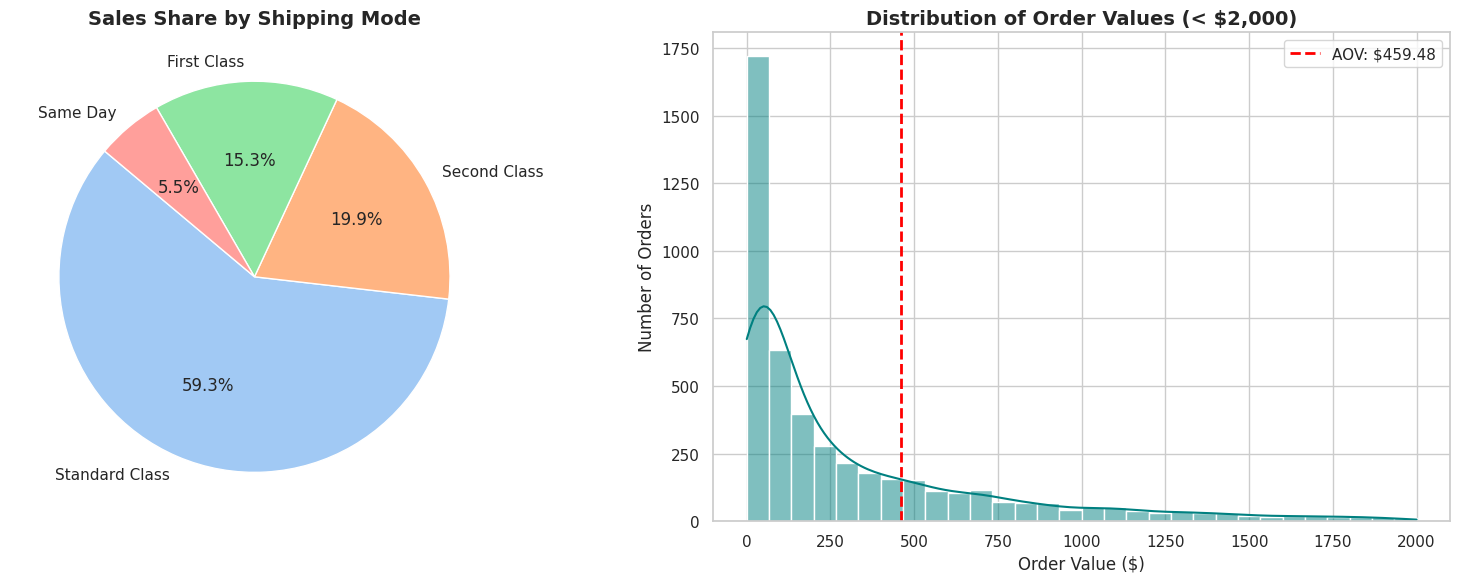

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Shipping Mode Market Share (Pie Chart)
axes[0].pie(
    ship_mode_perf['Total_Sales'],
    labels=ship_mode_perf['Ship_Mode'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')[0:4]
)
axes[0].set_title('Sales Share by Shipping Mode', fontsize=14, fontweight='bold')

# Chart 2: Order Value Distribution (Histogram)
# Filter out extreme outliers for a cleaner visualization look
sns.histplot(
    order_totals[order_totals < 2000],
    kde=True,
    ax=axes[1],
    color='teal',
    bins=30
)
axes[1].axvline(aov, color='red', linestyle='--', linewidth=2, label=f'AOV: ${aov:.2f}')
axes[1].set_title('Distribution of Order Values (< $2,000)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Order Value ($)', fontsize=12)
axes[1].set_ylabel('Number of Orders', fontsize=12)
axes[1].legend()

plt.tight_layout()
plt.show()